In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df = pd.read_csv(url)
print(df.head())

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  


In [3]:
df = df[["mpg", "displacement"]]
print(df.head())

    mpg  displacement
0  18.0         307.0
1  15.0         350.0
2  18.0         318.0
3  16.0         304.0
4  17.0         302.0


In [4]:
df.shape

(398, 2)

In [7]:
X = df[["displacement"]]
y = df["mpg"]

In [8]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [9]:
X_train.shape, X_test.shape

((318, 1), (80, 1))

Linear Regression......

In [10]:
linear_model = LinearRegression()
linear_model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [11]:
linear_pred = linear_model.predict(X_test)
linear_mse = mean_squared_error(y_test,linear_pred)
linear_r2 = r2_score(y_test,linear_pred)
print(linear_mse)
print(linear_r2)

18.102543998358946
0.6633114869465596


Polynomial regression

In [12]:
degrees = [2,3,4]
results = []
for degree in degrees:
    model = Pipeline([
        ("poly",PolynomialFeatures(degree=degree)),
        ("linear", LinearRegression())
    ])
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results.append([degree, mse, r2])
results_df = pd.DataFrame(results,
                          columns=['Degree', 'MSE', 'R2'])

print("\nPolynomial Regression Results")
print(results_df)


Polynomial Regression Results
   Degree        MSE        R2
0       2  15.107354  0.719019
1       3  14.943632  0.722064
2       4  14.961487  0.721732


Visualization

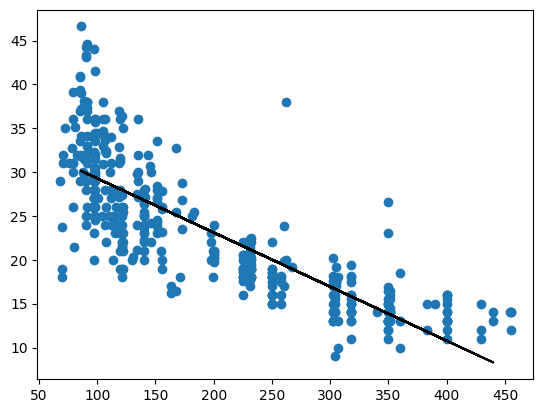

In [17]:
plt.figure()
plt.scatter(X,y)
plt.plot(X_test,linear_pred, color="black")
plt.show()

/home/student/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/home/student/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/home/student/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/home/student/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


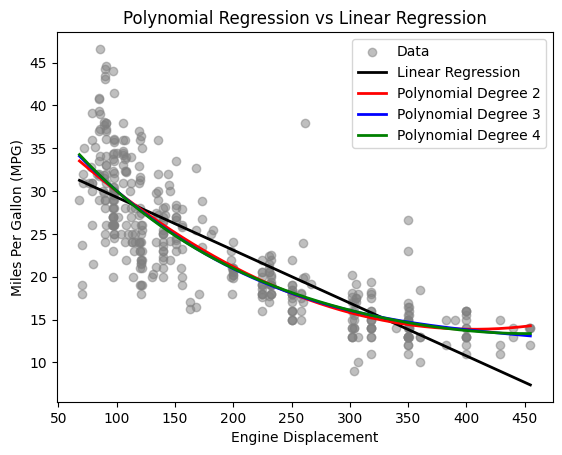

In [23]:
plt.figure()
plt.scatter(X, y, color='gray', alpha=0.5, label='Data')

# X values for smooth curve
X_range = np.linspace(
    X.min().values[0],
    X.max().values[0],
    300
).reshape(-1,1)

# Linear regression line
plt.plot(
    X_range,
    linear_model.predict(X_range),
    color='black',
    linewidth=2,
    label='Linear Regression'
)
# Polynomial curves
colors = ['red', 'blue', 'green']

for degree, color in zip(degrees, colors):

    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree)),
        ('linear', LinearRegression())
    ])

    model.fit(X, y)

    y_curve = model.predict(X_range)

    plt.plot(
        X_range,
        y_curve,
        color=color,
        linewidth=2,
        label=f'Polynomial Degree {degree}'
    )
plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")
plt.title("Polynomial Regression vs Linear Regression")
plt.legend()
plt.show()


In [25]:
print("\nComparison Summary")
print(f"Linear Regression -> MSE: {linear_mse:.3f}, R2: {linear_r2:.3f}")

for row in results:
    print(f"Degree {row[0]} -> MSE: {row[1]:.4f}, R2: {row[2]:.4f}")


Comparison Summary
Linear Regression -> MSE: 18.103, R2: 0.663
Degree 2 -> MSE: 15.1074, R2: 0.7190
Degree 3 -> MSE: 14.9436, R2: 0.7221
Degree 4 -> MSE: 14.9615, R2: 0.7217
